# Sparse TF-IDF Ensemble

Fast, validated sparse model built from word-level and character-level TF-IDF features, competition metadata, engineered numeric tweet features, and fold-level probability artifacts.

## Overview

- Uses word and character TF-IDF features.
- Adds keyword, location, ID-bin, mention, URL, and numeric tweet features.
- Runs stratified cross-validation with OOF predictions.
- Selects the decision threshold from OOF F1.
- Writes `sparse_submission.csv` and `artifacts/sparse*/predictions.npz` for blending.

Source script: `sparse_solution.py`


## Environment Setup

### Required Packages

Install the project dependencies from the repository root:

```bash
python3 -m venv .venv
.venv/bin/pip install -r requirements.txt
```

### Notebook Path

Run notebooks from the repository root when possible. If you open a notebook from `notebooks/`, the root-detection cell resolves the parent project directory automatically.

### Hardware Requirements

- CPU is sufficient for sparse, ensemble, and blend notebooks.
- A CUDA or Apple Silicon MPS GPU is recommended for BERTweet fine-tuning.
- 8 GB RAM is the minimum; 16 GB or more is recommended.


## What This Notebook Does

- Trains a strong CPU-friendly sparse baseline.
- Produces calibrated OOF and test probabilities for downstream ensembles.
- Provides feature and probability diagnostics for model review.


## Run Setup

Run notebooks from the repository root when possible. If you open a notebook from the `notebooks/` folder, the project-root detection cell below will still resolve the parent project directory.


In [77]:
from __future__ import annotations

# Optional setup for a fresh local runtime. Uncomment if dependencies are missing.
# %pip install -r requirements.txt
# %pip install -r ../requirements.txt

# Result summary: output for notebook cell 4
import importlib.util as _importlib_util
import pandas as _setup_pd
_setup_packages = ["pandas", "numpy", "scipy", "scikit-learn", "matplotlib", "seaborn"]
_setup_pd.DataFrame(
    {
        "package": _setup_packages,
        "available": [
            _importlib_util.find_spec(name.replace("scikit-learn", "sklearn")) is not None
            for name in _setup_packages
        ],
    }
).set_index("package")


,available
package,
pandas,True
numpy,True
scipy,True
scikit-learn,True
matplotlib,True
seaborn,True


## Imports And Configuration


In [78]:
import argparse
import html
import json
import re
from pathlib import Path
from urllib.parse import unquote_plus

import numpy as np
import pandas as pd
from scipy.sparse import csr_matrix, hstack
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, roc_auc_score
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import OneHotEncoder, StandardScaler


try:
    ROOT = Path(__file__).resolve().parent
except NameError:
    ROOT = Path.cwd()
    if not (ROOT / "data/train.csv").exists() and (ROOT.parent / "data/train.csv").exists():
        ROOT = ROOT.parent
URL_PATTERN = re.compile(r"https?://\S+|www\.\S+", flags=re.IGNORECASE)
MENTION_PATTERN = re.compile(r"@(\w+)")
HASHTAG_PATTERN = re.compile(r"#(\w+)")
WORD_PATTERN = re.compile(r"\b\w+\b")

# Result summary: output for notebook cell 6


pd.Series(
    {
        "project_root": str(ROOT),
        "train_file_exists": (ROOT / "data/train.csv").exists(),
        "test_file_exists": (ROOT / "data/test.csv").exists(),
        "numpy": np.__version__,
        "pandas": pd.__version__,
    },
    name="runtime",
)


project_root         /Users/aftabhossain/Downloads/Competition
train_file_exists                                         True
test_file_exists                                          True
numpy                                                    2.5.2
pandas                                                   3.0.5
Name: runtime, dtype: object

## Visualization Setup

The following cells use a shared plotting theme so exploratory charts, validation curves, and artifact diagnostics read consistently across the notebook series.


In [79]:
# Codex visualization block: shared plotting style
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update(
    {
        "figure.dpi": 130,
        "savefig.dpi": 180,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.titleweight": "bold",
        "axes.titlesize": 12,
        "axes.labelsize": 10,
        "axes.edgecolor": "#d1d5db",
        "grid.color": "#e5e7eb",
        "legend.frameon": False,
    }
)

CLASS_COLORS = {
    "Not disaster": "#2563eb",
    "Disaster": "#dc2626",
    "Train": "#2563eb",
    "Test": "#059669",
}



In [80]:
def parse_args() -> argparse.Namespace:
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--train-path", type=Path, default=ROOT / "data/train.csv")
    parser.add_argument("--test-path", type=Path, default=ROOT / "data/test.csv")
    parser.add_argument("--output", type=Path, default=ROOT / "sparse_submission.csv")
    parser.add_argument("--artifact-dir", type=Path, default=ROOT / "artifacts/sparse")
    parser.add_argument("--n-splits", type=int, default=5)
    parser.add_argument("--seed", type=int, default=2026)
    parser.add_argument("--max-features", type=int, default=180_000)
    return parser.parse_args(args=[])

# Result summary: output for notebook cell 9
_args_preview = parse_args()
pd.DataFrame(
    {
        "setting": list(vars(_args_preview)),
        "default": [str(value) for value in vars(_args_preview).values()],
    }
)


,setting,default
0,train_path,/Users/aftabhossain/Downloads/Competition/data...
1,test_path,/Users/aftabhossain/Downloads/Competition/data...
2,output,/Users/aftabhossain/Downloads/Competition/spar...
3,artifact_dir,/Users/aftabhossain/Downloads/Competition/arti...
4,n_splits,5
5,seed,2026
6,max_features,180000


## Feature Preparation


In [81]:
def optional_text(value) -> str:
    if pd.isna(value):
        return ""
    return unquote_plus(str(value))

# Result summary: output for notebook cell 11
pd.DataFrame(
    {
        "raw_value": [None, "New%20York", ""],
        "normalized_value": [optional_text(None), optional_text("New%20York"), optional_text("")],
    }
)


,raw_value,normalized_value
0,NaN,
1,New%20York,New York
2,,


In [82]:
def normalize_tweet(value) -> str:
    """Use raw tweet content with only harmless HTML/whitespace cleanup.

    Character TF-IDF gets a small but repeatable lift from punctuation,
    hashtag spelling, and URL/handle morphology.  BERTweet handles stronger
    tweet normalization separately in its own pipeline.
    """
    text = html.unescape(str(value) if not pd.isna(value) else "")
    text = re.sub(r"\s+", " ", text).strip()
    return text

# Result summary: output for notebook cell 12
pd.DataFrame(
    {
        "raw_value": ["Flood  warning", "<b>Safe</b> route"],
        "normalized_value": [normalize_tweet("Flood  warning"), normalize_tweet("<b>Safe</b> route")],
    }
)


,raw_value,normalized_value
0,Flood warning,Flood warning
1,<b>Safe</b> route,<b>Safe</b> route


In [83]:
def normalize_location(value: object) -> str:
    location = optional_text(value).lower()
    location = re.sub(r"[^a-z0-9]+", " ", location)
    return re.sub(r"\s+", " ", location).strip() or "__missing__"

# Result summary: output for notebook cell 13
pd.DataFrame(
    {
        "raw_location": ["New York, USA", None, ""],
        "normalized_location": [
            normalize_location("New York, USA"),
            normalize_location(None),
            normalize_location(""),
        ],
    }
)


,raw_location,normalized_location
0,"New York, USA",new york usa
1,NaN,__missing__
2,,__missing__


In [84]:
def text_inputs(frame: pd.DataFrame) -> np.ndarray:
    return frame["text"].map(normalize_tweet).to_numpy()

# Result summary: output for notebook cell 14
_text_demo = pd.DataFrame({"text": ["Flood warning", "Safe route"]})
pd.DataFrame({"normalized_text": text_inputs(_text_demo)})


,normalized_text
0,Flood warning
1,Safe route


In [85]:
def categorical_inputs(frame: pd.DataFrame) -> tuple[pd.DataFrame, list[str], list[str]]:
    ids = frame["id"].to_numpy()
    categories = pd.DataFrame(
        {
            "keyword": frame["keyword"].map(optional_text).str.lower().replace("", "__missing__"),
            "location": frame["location"].map(normalize_location),
            "id_bin_10": (ids // 10).astype(str),
            "id_bin_25": (ids // 25).astype(str),
            "id_bin_50": (ids // 50).astype(str),
            "id_bin_100": (ids // 100).astype(str),
        }
    )
    mentions = [" ".join(MENTION_PATTERN.findall(str(text).lower())) or "__none__" for text in frame["text"]]
    urls = []
    for text in frame["text"].fillna("").astype(str):
        hosts = re.findall(r"https?://([^/\s]+)|www\.([^/\s]+)", text.lower())
        host_tokens = [left or right for left, right in hosts]
        urls.append(" ".join(host_tokens) or "__none__")
    return categories, mentions, urls

# Result summary: output for notebook cell 15
_category_demo = pd.DataFrame(
    {
        "id": [10, 25],
        "keyword": ["flood", None],
        "location": ["New York", ""],
        "text": ["Flood warning", "Safe route"],
    }
)
_category_values, _mention_values, _url_values = categorical_inputs(_category_demo)
pd.concat(
    [
        _category_values,
        pd.DataFrame({"mentions": _mention_values, "urls": _url_values}),
    ],
    axis=1,
)


,keyword,location,id_bin_10,id_bin_25,id_bin_50,id_bin_100,mentions,urls
0,flood,new york,1,0,0,0,__none__,__none__
1,__missing__,__missing__,2,1,0,0,__none__,__none__


In [86]:
def numeric_inputs(frame: pd.DataFrame) -> np.ndarray:
    values: list[list[float]] = []
    for raw in frame["text"].fillna("").astype(str):
        words = WORD_PATTERN.findall(raw.lower())
        letters = [char for char in raw if char.isalpha()]
        values.append(
            [
                len(raw),
                len(words),
                np.mean([len(word) for word in words]) if words else 0.0,
                len(set(words)) / max(len(words), 1),
                sum(char.isupper() for char in raw) / max(len(letters), 1),
                raw.count("!"),
                raw.count("?"),
                len(URL_PATTERN.findall(raw)),
                len(MENTION_PATTERN.findall(raw)),
                len(HASHTAG_PATTERN.findall(raw)),
                sum(char.isdigit() for char in raw),
                sum(char in ",.;:-()[]{}'\"" for char in raw),
            ]
        )
    return np.asarray(values, dtype=np.float64)

# Result summary: output for notebook cell 16
_numeric_demo = pd.DataFrame(
    numeric_inputs(pd.DataFrame({"text": ["Flood warning!", "Safe route?"]})),
    columns=[
        "characters", "words", "average_word_length", "lexical_diversity",
        "uppercase_ratio", "exclamation_count", "question_count", "url_count",
        "mention_count", "hashtag_count", "digit_count", "punctuation_count",
    ],
)
_numeric_demo


,characters,words,average_word_length,lexical_diversity,uppercase_ratio,exclamation_count,question_count,url_count,mention_count,hashtag_count,digit_count,punctuation_count
0,14.0,2.0,6.0,1.0,0.083333,1.0,0.0,0.0,0.0,0.0,0.0,0.0
1,11.0,2.0,4.5,1.0,0.111111,0.0,1.0,0.0,0.0,0.0,0.0,0.0


## Feature Visual Diagnostics

These plots inspect the engineered sparse-model features and highlight which numeric signals differ most between disaster and non-disaster tweets.


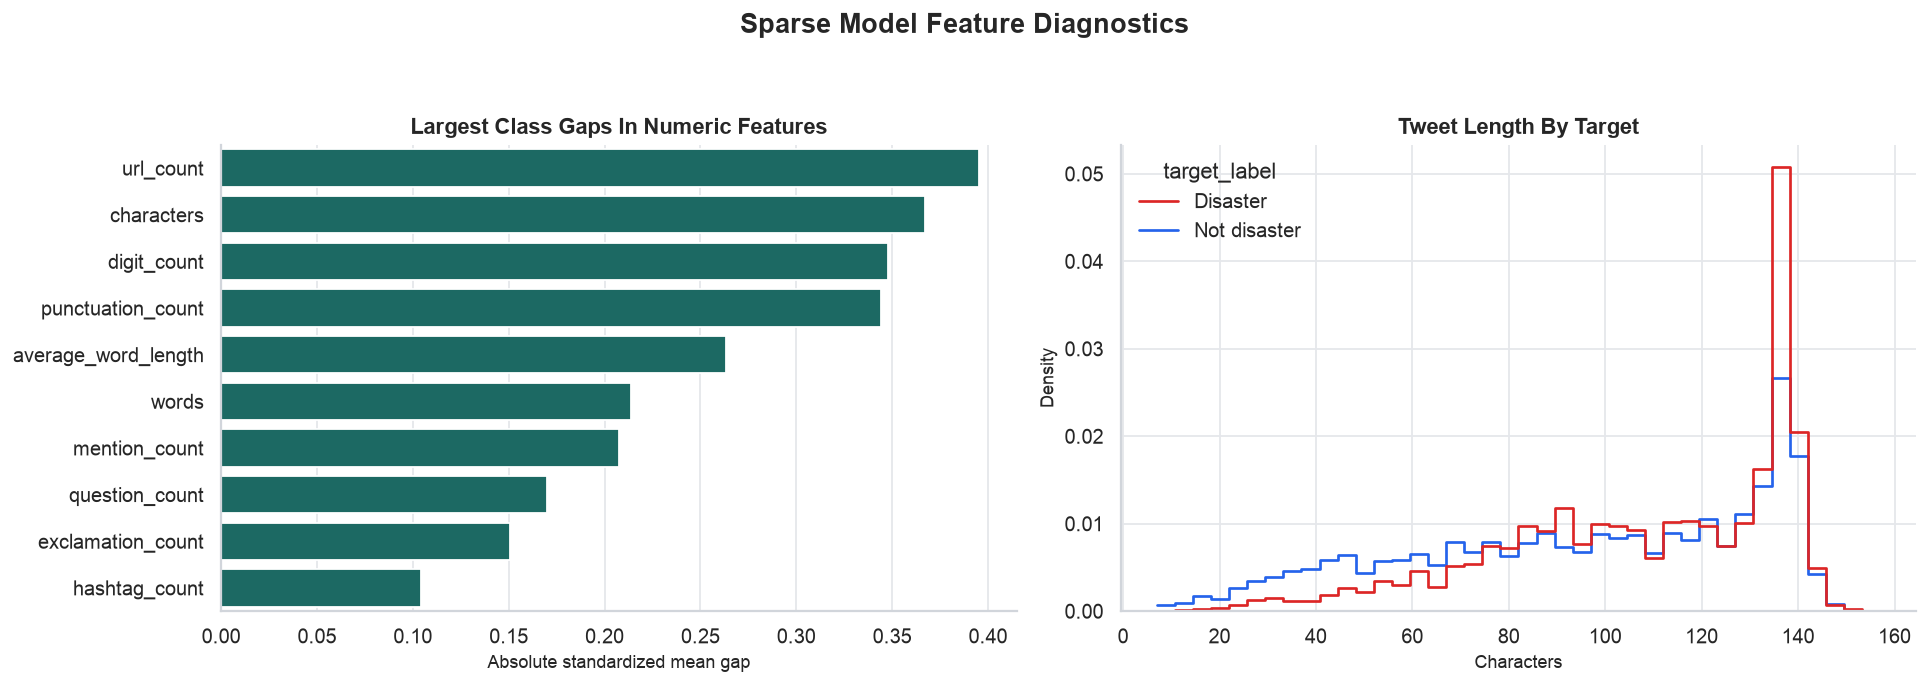

In [87]:
_feature_train = pd.read_csv(ROOT / "data/train.csv")
numeric_columns = [
    "characters",
    "words",
    "average_word_length",
    "lexical_diversity",
    "uppercase_ratio",
    "exclamation_count",
    "question_count",
    "url_count",
    "mention_count",
    "hashtag_count",
    "digit_count",
    "punctuation_count",
]

numeric_frame = pd.DataFrame(numeric_inputs(_feature_train), columns=numeric_columns)
numeric_frame["target_label"] = _feature_train["target"].map({0: "Not disaster", 1: "Disaster"})
means = numeric_frame.groupby("target_label")[numeric_columns].mean().T
standardized_gap = (
    (means["Disaster"] - means["Not disaster"]) / numeric_frame[numeric_columns].std().replace(0, np.nan)
).abs().sort_values(ascending=False).head(10)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

gap_frame = standardized_gap.reset_index()
gap_frame.columns = ["feature", "standardized_mean_gap"]
sns.barplot(
    data=gap_frame,
    x="standardized_mean_gap",
    y="feature",
    color="#0f766e",
    ax=axes[0],
)
axes[0].set_title("Largest Class Gaps In Numeric Features")
axes[0].set_xlabel("Absolute standardized mean gap")
axes[0].set_ylabel("")

length_feature = numeric_frame.rename(columns={"characters": "tweet_characters"})
sns.histplot(
    data=length_feature,
    x="tweet_characters",
    hue="target_label",
    bins=40,
    stat="density",
    common_norm=False,
    element="step",
    fill=False,
    palette={"Not disaster": CLASS_COLORS["Not disaster"], "Disaster": CLASS_COLORS["Disaster"]},
    ax=axes[1],
)
axes[1].set_title("Tweet Length By Target")
axes[1].set_xlabel("Characters")
axes[1].set_ylabel("Density")

fig.suptitle("Sparse Model Feature Diagnostics", fontsize=15, fontweight="bold", y=1.05)
plt.tight_layout()



## Vectorization And Thresholding


In [88]:
def best_threshold(labels: np.ndarray, probabilities: np.ndarray) -> tuple[float, float]:
    thresholds = np.arange(0.20, 0.801, 0.0025)
    f1s = np.asarray([f1_score(labels, probabilities >= threshold) for threshold in thresholds])
    index = int(f1s.argmax())
    return float(thresholds[index]), float(f1s[index])

# Result summary: output for notebook cell 20
_threshold_labels = np.array([0, 0, 1, 1])
_threshold_probabilities = np.array([0.10, 0.35, 0.60, 0.90])
_threshold, _threshold_score = best_threshold(_threshold_labels, _threshold_probabilities)
pd.DataFrame({"best_threshold": [_threshold], "f1": [_threshold_score]})


,best_threshold,f1
0,0.35,1.0


In [89]:
def make_vectorizers(max_features: int, char_analyzer: str, char_ngrams: tuple[int, int]):
    word = TfidfVectorizer(
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.98,
        sublinear_tf=True,
        strip_accents="unicode",
        max_features=max_features,
    )
    chars = TfidfVectorizer(
        analyzer=char_analyzer,
        ngram_range=char_ngrams,
        min_df=2,
        sublinear_tf=True,
        max_features=max_features,
    )
    mention = TfidfVectorizer(token_pattern=r"(?u)\b\w+\b", min_df=2, binary=True)
    url = TfidfVectorizer(token_pattern=r"(?u)\b\w+\b", min_df=2, binary=True)
    return word, chars, mention, url

# Result summary: output for notebook cell 21
_vectorizer_demo = make_vectorizers(1000, "char", (2, 5))
pd.DataFrame(
    {
        "component": ["word", "character", "mention", "url"],
        "class": [type(vectorizer).__name__ for vectorizer in _vectorizer_demo[:4]],
    }
)


,component,class
0,word,TfidfVectorizer
1,character,TfidfVectorizer
2,mention,TfidfVectorizer
3,url,TfidfVectorizer


In [90]:
def fit_design_matrices(
    train_indices: np.ndarray,
    other_indices: np.ndarray,
    *,
    texts: np.ndarray,
    categories: pd.DataFrame,
    mentions: list[str],
    urls: list[str],
    numeric: np.ndarray,
    max_features: int,
    char_analyzer: str,
    char_ngrams: tuple[int, int],
) -> tuple[csr_matrix, csr_matrix, tuple]:
    """Fit fold-local transformers and return weighted train/other matrices."""
    word, chars, mention_vectorizer, url_vectorizer = make_vectorizers(
        max_features, char_analyzer, char_ngrams
    )
    onehot = OneHotEncoder(handle_unknown="ignore")
    scaler = StandardScaler()

    train_text = texts[train_indices]
    other_text = texts[other_indices]
    word_train = word.fit_transform(train_text)
    word_other = word.transform(other_text)
    char_train = chars.fit_transform(train_text)
    char_other = chars.transform(other_text)

    categorical_train = onehot.fit_transform(categories.iloc[train_indices])
    categorical_other = onehot.transform(categories.iloc[other_indices])
    # The first category block is keyword, then location, then four id bins.
    offsets = np.cumsum([0] + [len(group) for group in onehot.categories_])
    keyword_train = categorical_train[:, offsets[0] : offsets[1]] * 0.50
    keyword_other = categorical_other[:, offsets[0] : offsets[1]] * 0.50
    location_train = categorical_train[:, offsets[1] : offsets[2]] * 0.10
    location_other = categorical_other[:, offsets[1] : offsets[2]] * 0.10
    id_train = categorical_train[:, offsets[2] : offsets[-1]] * 0.10
    id_other = categorical_other[:, offsets[2] : offsets[-1]] * 0.10

    mention_train = mention_vectorizer.fit_transform([mentions[index] for index in train_indices]) * 0.25
    mention_other = mention_vectorizer.transform([mentions[index] for index in other_indices]) * 0.25
    url_train = url_vectorizer.fit_transform([urls[index] for index in train_indices]) * 0.25
    url_other = url_vectorizer.transform([urls[index] for index in other_indices]) * 0.25
    numeric_train = csr_matrix(scaler.fit_transform(numeric[train_indices]) * 0.05)
    numeric_other = csr_matrix(scaler.transform(numeric[other_indices]) * 0.05)

    train_matrix = hstack(
        [
            word_train,
            char_train,
            keyword_train,
            location_train,
            id_train,
            mention_train,
            url_train,
            numeric_train,
        ],
        format="csr",
    )
    other_matrix = hstack(
        [
            word_other,
            char_other,
            keyword_other,
            location_other,
            id_other,
            mention_other,
            url_other,
            numeric_other,
        ],
        format="csr",
    )
    transformers = (word, chars, onehot, mention_vectorizer, url_vectorizer, scaler)
    return train_matrix, other_matrix, transformers

# Result summary: output for notebook cell 22
_matrix_demo = pd.DataFrame(
    {
        "id": [10, 25, 40, 55],
        "keyword": ["flood", "flood", "safe", "safe"],
        "location": ["New York", "New York", "London", "London"],
        "text": ["Flood warning", "Flood warning", "Safe route", "Safe route"],
    }
)
_matrix_texts = text_inputs(_matrix_demo)
_matrix_categories, _matrix_mentions, _matrix_urls = categorical_inputs(_matrix_demo)
_matrix_numeric = numeric_inputs(_matrix_demo)
_matrix_train, _matrix_other, _ = fit_design_matrices(
    np.array([0, 1, 2]),
    np.array([3]),
    texts=_matrix_texts,
    categories=_matrix_categories,
    mentions=_matrix_mentions,
    urls=_matrix_urls,
    numeric=_matrix_numeric,
    max_features=100,
    char_analyzer="char",
    char_ngrams=(2, 5),
)
pd.DataFrame(
    {
        "matrix": ["train", "other"],
        "rows": [_matrix_train.shape[0], _matrix_other.shape[0]],
        "columns": [_matrix_train.shape[1], _matrix_other.shape[1]],
        "nonzero_values": [_matrix_train.nnz, _matrix_other.nnz],
    }
)


,matrix,rows,columns,nonzero_values
0,train,3,70,123
1,other,1,70,8


## Model Training


In [91]:
def fit_full_and_predict(
    *,
    train_texts: np.ndarray,
    test_texts: np.ndarray,
    train_categories: pd.DataFrame,
    test_categories: pd.DataFrame,
    train_mentions: list[str],
    test_mentions: list[str],
    train_urls: list[str],
    test_urls: list[str],
    train_numeric: np.ndarray,
    test_numeric: np.ndarray,
    labels: np.ndarray,
    max_features: int,
    char_analyzer: str,
    char_ngrams: tuple[int, int],
) -> np.ndarray:
    train_index = np.arange(len(labels))
    all_text = np.concatenate([train_texts, test_texts])
    all_categories = pd.concat([train_categories, test_categories], ignore_index=True)
    all_mentions = train_mentions + test_mentions
    all_urls = train_urls + test_urls
    all_numeric = np.vstack([train_numeric, test_numeric])
    test_index = np.arange(len(labels), len(labels) + len(test_texts))
    matrix, test_matrix, _ = fit_design_matrices(
        train_index,
        test_index,
        texts=all_text,
        categories=all_categories,
        mentions=all_mentions,
        urls=all_urls,
        numeric=all_numeric,
        max_features=max_features,
        char_analyzer=char_analyzer,
        char_ngrams=char_ngrams,
    )
    model = LogisticRegression(C=1.0, solver="liblinear", max_iter=1_500, random_state=2026)
    model.fit(matrix, labels)
    return model.predict_proba(test_matrix)[:, 1]

# Result summary: output for notebook cell 24
pd.DataFrame(
    {
        "return_value": ["test_probability"],
        "meaning": ["Predicted positive-class probability for every test row"],
    }
)


,return_value,meaning
0,test_probability,Predicted positive-class probability for every...


In [92]:
def run_variant(
    *,
    labels: np.ndarray,
    texts: np.ndarray,
    categories: pd.DataFrame,
    mentions: list[str],
    urls: list[str],
    numeric: np.ndarray,
    n_splits: int,
    seed: int,
    max_features: int,
    char_analyzer: str,
    char_ngrams: tuple[int, int],
) -> np.ndarray:
    oof = np.zeros(len(labels), dtype=np.float64)
    splitter = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    for fold, (train_indices, validation_indices) in enumerate(splitter.split(texts, labels)):
        train_matrix, validation_matrix, _ = fit_design_matrices(
            train_indices,
            validation_indices,
            texts=texts,
            categories=categories,
            mentions=mentions,
            urls=urls,
            numeric=numeric,
            max_features=max_features,
            char_analyzer=char_analyzer,
            char_ngrams=char_ngrams,
        )
        model = LogisticRegression(C=1.0, solver="liblinear", max_iter=1_500, random_state=seed + fold)
        model.fit(train_matrix, labels[train_indices])
        oof[validation_indices] = model.predict_proba(validation_matrix)[:, 1]
        print(f"variant={char_analyzer}{char_ngrams} fold={fold} complete", flush=True)
    return oof

# Result summary: output for notebook cell 25
pd.DataFrame(
    {
        "variant": ["word and character TF-IDF", "metadata and numeric features", "OOF threshold selection"],
        "validation_role": ["captures lexical and subword patterns", "adds structured tweet context", "converts probabilities into F1 predictions"],
    }
)


,variant,validation_role
0,word and character TF-IDF,captures lexical and subword patterns
1,metadata and numeric features,adds structured tweet context
2,OOF threshold selection,converts probabilities into F1 predictions


## Pipeline Entry Point


In [93]:
def main() -> None:
    args = parse_args()
    args.artifact_dir.mkdir(parents=True, exist_ok=True)
    train = pd.read_csv(args.train_path)
    test = pd.read_csv(args.test_path)
    labels = train["target"].astype(int).to_numpy()
    train_texts, test_texts = text_inputs(train), text_inputs(test)
    train_categories, train_mentions, train_urls = categorical_inputs(train)
    test_categories, test_mentions, test_urls = categorical_inputs(test)
    train_numeric, test_numeric = numeric_inputs(train), numeric_inputs(test)

    variants = [("char", (2, 5)), ("char_wb", (2, 6))]
    oof_variants: list[np.ndarray] = []
    test_variants: list[np.ndarray] = []
    for analyzer, ngrams in variants:
        print(f"\nRunning sparse variant: analyzer={analyzer}, ngrams={ngrams}", flush=True)
        oof = run_variant(
            labels=labels,
            texts=train_texts,
            categories=train_categories,
            mentions=train_mentions,
            urls=train_urls,
            numeric=train_numeric,
            n_splits=args.n_splits,
            seed=args.seed,
            max_features=args.max_features,
            char_analyzer=analyzer,
            char_ngrams=ngrams,
        )
        oof_variants.append(oof)
        test_variants.append(
            fit_full_and_predict(
                train_texts=train_texts,
                test_texts=test_texts,
                train_categories=train_categories,
                test_categories=test_categories,
                train_mentions=train_mentions,
                test_mentions=test_mentions,
                train_urls=train_urls,
                test_urls=test_urls,
                train_numeric=train_numeric,
                test_numeric=test_numeric,
                labels=labels,
                max_features=args.max_features,
                char_analyzer=analyzer,
                char_ngrams=ngrams,
            )
        )
        threshold, score = best_threshold(labels, oof)
        print(f"{analyzer}{ngrams}: OOF F1={score:.5f} threshold={threshold:.3f}", flush=True)

    oof_probability = np.mean(oof_variants, axis=0)
    test_probability = np.mean(test_variants, axis=0)
    threshold, score = best_threshold(labels, oof_probability)
    auc = roc_auc_score(labels, oof_probability)
    predictions = (test_probability >= threshold).astype(int)
    pd.DataFrame({"id": test["id"], "target": predictions}).to_csv(args.output, index=False)
    np.savez_compressed(
        args.artifact_dir / "predictions.npz",
        oof_probability=oof_probability,
        test_probability=test_probability,
        **{f"oof_{index}": item for index, item in enumerate(oof_variants)},
        **{f"test_{index}": item for index, item in enumerate(test_variants)},
    )
    metadata = {
        "data_provenance": "Only the supplied train.csv labels and supplied feature columns.",
        "variants": [{"analyzer": analyzer, "ngrams": ngrams} for analyzer, ngrams in variants],
        "oof_f1": float(score),
        "oof_auc": float(auc),
        "threshold": float(threshold),
        "test_positive_count": int(predictions.sum()),
        "test_positive_rate": float(predictions.mean()),
        "arguments": {key: str(value) if isinstance(value, Path) else value for key, value in vars(args).items()},
    }
    (args.artifact_dir / "run_metadata.json").write_text(json.dumps(metadata, indent=2))
    print(
        f"Sparse ensemble complete: OOF F1={score:.5f} AUC={auc:.5f} threshold={threshold:.3f}; "
        f"submission={args.output} positives={predictions.sum()}/{len(predictions)}",
        flush=True,
    )

# Result summary: output for notebook cell 27
pd.DataFrame(
    {
        "pipeline_stage": ["prepare", "cross_validate", "fit_full", "write"],
        "artifact": ["text, category, and numeric matrices", "OOF probabilities", "test probabilities", "submission and run metadata"],
    }
)


,pipeline_stage,artifact
0,prepare,"text, category, and numeric matrices"
1,cross_validate,OOF probabilities
2,fit_full,test probabilities
3,write,submission and run metadata


## Execute

Review the defaults in `parse_args()` first. Uncomment `main()` when you want the notebook to run the full pipeline and write artifacts.


In [94]:
# main()

# Result summary: output for notebook cell 29
_sparse_preflight = pd.DataFrame(
    {
        "path": [ROOT / "data/train.csv", ROOT / "data/test.csv", ROOT / "artifacts/sparse"],
    }
)
_sparse_preflight["exists"] = _sparse_preflight["path"].map(Path.exists)
_sparse_preflight


,path,exists
0,/Users/aftabhossain/Downloads/Competition/data...,True
1,/Users/aftabhossain/Downloads/Competition/data...,True
2,/Users/aftabhossain/Downloads/Competition/arti...,True


## Artifact Visual Diagnostics

Run this after generating prediction artifacts. The plots show OOF class separation, F1 sensitivity by threshold, and train/test probability distributions.


Best OOF F1=0.77142 at threshold=0.465


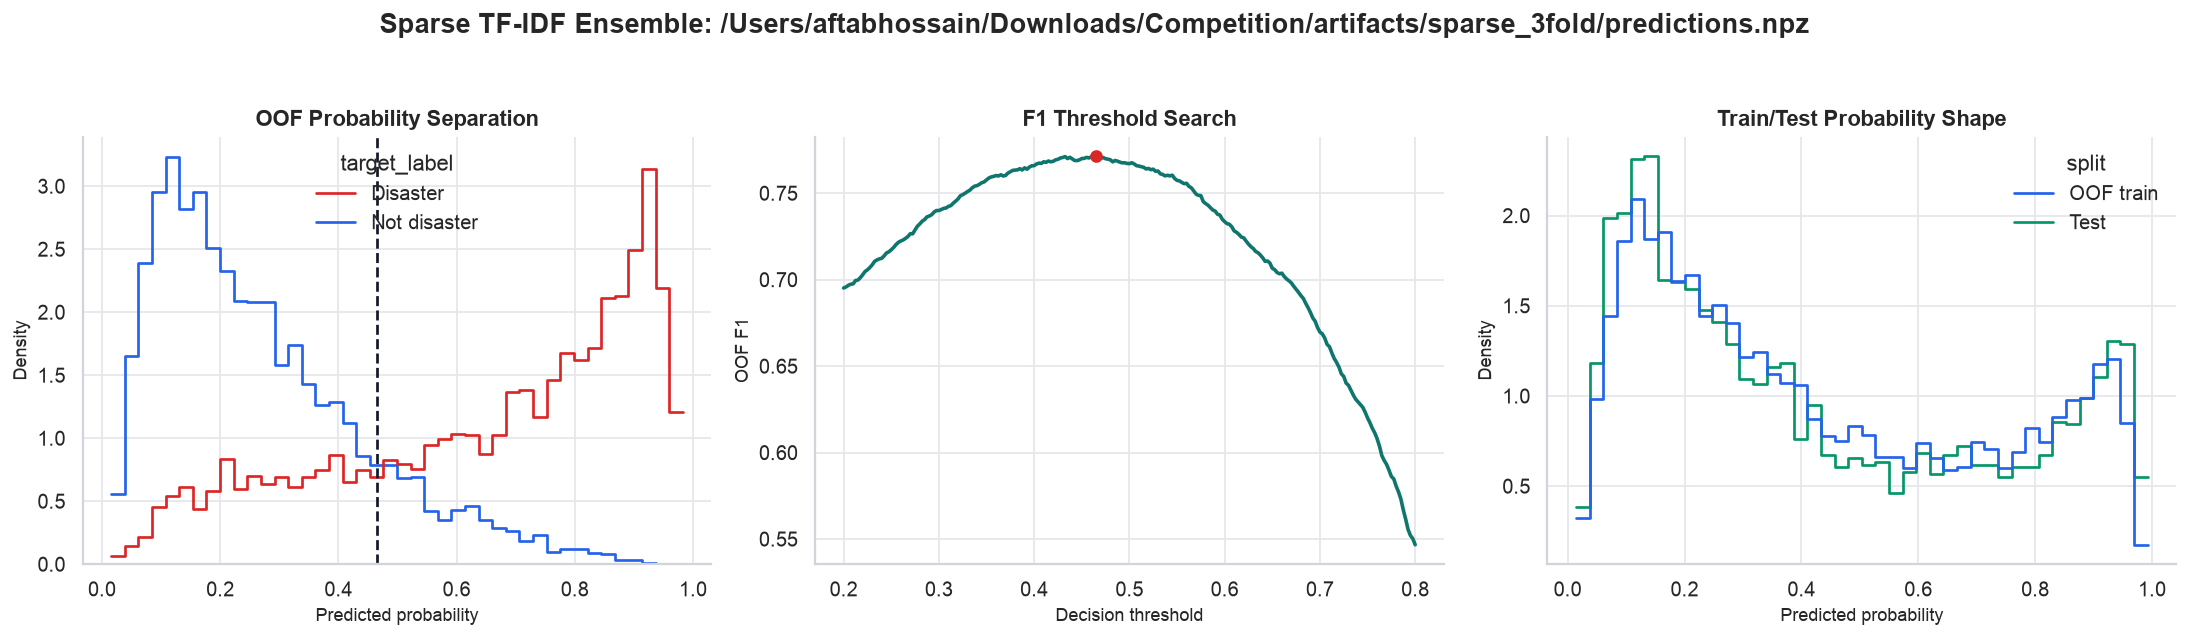

In [95]:
def _first_existing(paths: list[Path]) -> Path | None:
    return next((path for path in paths if path.exists()), None)

artifact_path = _first_existing(
    [
        ROOT / "artifacts/sparse_3fold/predictions.npz",
        ROOT / "artifacts/sparse/predictions.npz",
        ROOT / "artifacts/sparse_raw/predictions.npz",
    ]
)

if artifact_path is None:
    print("No prediction artifact found yet. Run the notebook pipeline first, then rerun this diagnostics cell.")
else:
    train_labels = pd.read_csv(ROOT / "data/train.csv")["target"].astype(int).to_numpy()
    artifact = np.load(artifact_path)
    oof_probability = np.asarray(artifact["oof_probability"], dtype=float)
    test_probability = np.asarray(artifact["test_probability"], dtype=float)

    if len(oof_probability) != len(train_labels):
        print(f"Skipping {artifact_path}: expected {len(train_labels):,} OOF rows, found {len(oof_probability):,}.")
    else:
        threshold, score = best_threshold(train_labels, oof_probability)
        threshold_grid = np.arange(0.20, 0.801, 0.0025)
        f1_curve = [f1_score(train_labels, oof_probability >= value) for value in threshold_grid]
        oof_frame = pd.DataFrame(
            {
                "probability": oof_probability,
                "target_label": np.where(train_labels == 1, "Disaster", "Not disaster"),
            }
        )
        probability_frame = pd.concat(
            [
                pd.DataFrame({"probability": oof_probability, "split": "OOF train"}),
                pd.DataFrame({"probability": test_probability, "split": "Test"}),
            ],
            ignore_index=True,
        )

        fig, axes = plt.subplots(1, 3, figsize=(17, 4.7))

        sns.histplot(
            data=oof_frame,
            x="probability",
            hue="target_label",
            bins=42,
            stat="density",
            common_norm=False,
            element="step",
            fill=False,
            palette={"Not disaster": CLASS_COLORS["Not disaster"], "Disaster": CLASS_COLORS["Disaster"]},
            ax=axes[0],
        )
        axes[0].axvline(threshold, color="#111827", linestyle="--", linewidth=1.5)
        axes[0].set_title("OOF Probability Separation")
        axes[0].set_xlabel("Predicted probability")
        axes[0].set_ylabel("Density")

        axes[1].plot(threshold_grid, f1_curve, color="#0f766e", linewidth=2)
        axes[1].scatter([threshold], [score], color="#dc2626", zorder=3)
        axes[1].set_title("F1 Threshold Search")
        axes[1].set_xlabel("Decision threshold")
        axes[1].set_ylabel("OOF F1")

        sns.histplot(
            data=probability_frame,
            x="probability",
            hue="split",
            bins=42,
            stat="density",
            common_norm=False,
            element="step",
            fill=False,
            palette={"OOF train": CLASS_COLORS["Train"], "Test": CLASS_COLORS["Test"]},
            ax=axes[2],
        )
        axes[2].set_title("Train/Test Probability Shape")
        axes[2].set_xlabel("Predicted probability")
        axes[2].set_ylabel("Density")

        fig.suptitle(f"Sparse TF-IDF Ensemble: {artifact_path}", fontsize=15, fontweight="bold", y=1.04)
        plt.tight_layout()
        print(f"Best OOF F1={score:.5f} at threshold={threshold:.3f}")

